##### <img src=../figures/Brown_logo.svg width=50%>

## Data-Driven Design & Analyses of Structures & Materials (3dasm)

## Lecture 19

### Martin van der Schelling | <a href = "mailto: m.p.vanderschelling@tudelft.nl">m.p.vanderschelling@tudelft.nl</a>  | Doctoral Candidate

### Miguel A. Bessa | <a href = "mailto: miguel_bessa@brown.edu">miguel_bessa@brown.edu</a>  | Associate Professor

### Elvis Aguero | <a href = "mailto: elvis_vera@brown.edu">elvis_vera@brown.edu</a>  | PhD candidate

**What:** A lecture of the "3dasm" course

**Where:** This notebook comes from this [repository](https://github.com/bessagroup/3dasm_course)

**Reference for entire course:** Murphy, Kevin P. *Probabilistic machine learning: an introduction*. MIT press, 2022. Available online [here](https://probml.github.io/pml-book/book1.html)

**How:** We try to follow Murphy's book closely, but the sequence of Chapters and Sections is different. The intention is to use notebooks as an introduction to the topic and Murphy's book as a resource.
* If working offline: Go through this notebook and read the book.
* If attending class in person: listen to me (!) but also go through the notebook in your laptop at the same time. Read the book.
* If attending lectures remotely: listen to me (!) via Zoom and (ideally) use two screens where you have the notebook open in 1 screen and you see the lectures on the other. Read the book.

**References/resources to create this notebook:**
* [Car figure](https://korkortonline.se/en/theory/reaction-braking-stopping/)
* [`adda` documentation](https://bessagroup.github.io/adda/)

Apologies in advance if I missed some reference used in this notebook. Please contact me if that is the case, and I will gladly include it here.

## **OPTION 1**. Run this notebook **locally in your computer**:
1. Confirm that you have the '3dasm' mamba (or conda) environment (see Lecture 1).
2. Go to the 3dasm_course folder in your computer and pull the last updates of the [repository](https://github.com/bessagroup/3dasm_course):
```
git pull
```
    - Note: if you can't pull the repo due to conflicts (and you can't handle these conflicts), use this command (with **caution**!) and your repo becomes the same as the one online:
```
git reset --hard origin/main
```
3. Open command window and load jupyter notebook (it will open in your internet browser):
```
jupyter notebook
```
4. Open notebook of this Lecture and choose the '3dasm' kernel.

## **OPTION 2**. Use **Google's Colab** (no installation required, but times out if idle):

1. go to https://colab.research.google.com
2. login
3. File > Open notebook
4. click on Github (no need to login or authorize anything)
5. paste the git link: https://github.com/bessagroup/3dasm_course
6. click search and then click on the notebook for this Lecture.

Colab cannot run the agents of this notebook. You will see the recorded outputs, not new runs. To run a study yourself you need Option 1, with Claude Code installed (see Lecture 10).

In [1]:
# Basic plotting tools needed in Python.
import warnings; warnings.filterwarnings("ignore") # keeps the output of the notebook clean
from pathlib import Path
import matplotlib.pyplot as plt # import plotting tools to create figures
import numpy as np # import numpy to handle a lot of things!
import pandas as pd # to read the data
from IPython.display import SVG, Markdown, display
import importlib.util # to load the code that the agents write
from f3dasm import ExperimentData
from adda import Agent, Graph, AgenticRun # install it first (see "Installing adda" below)

rng = np.random.default_rng(0) # the random drivers of our experiments

# adda switches off its machinery for long studies (a notebook as deliverable, its reproduction check, hypotheses...)
LEAN = dict(pipeline_deliverable=False, reproduction_gate=False, hypothesis_ledger=False, verdict_validator=False,
            milestones_enabled=False, science_monitor=False, peer_interaction=False)

%config InlineBackend.figure_format = "retina" # render higher resolution images in the notebook
plt.rcParams["figure.figsize"] = (8,4) # rescale figure size appropriately for slides
pd.set_option('display.max_rows', 10) # To limit the number of rows to show in a dataframe, for presentation purposes

## Outline for today

* `adda`: the agentic layer of `f3dasm`
* The smallest workflow: one agent does Lecture 18 for us
* More flexibility:
    - our own tool, which keeps the truth to ourselves
    - a model for each agent

**Reading material**: This notebook + the [`adda` documentation](https://bessagroup.github.io/adda/).

## From `f3dasm` to `adda`

<center><img src="../figures/f3dasm_overview.svg" title="f3dasm overview" width="30%"></center>

In Lecture 18 we wrote every block of the data-driven process ourselves: the `Domain`, the sampler, the `DataGenerator`, the model.

`adda` (**A**gentic **D**ata-**D**riven **D**esign and **A**nalysis) is the agentic layer of `f3dasm`. A team of AI agents writes and runs the blocks. We decide the **problem**, the **team**, and how we **check** what comes back.

All the agents use **Haiku**, the cheapest model of the course. Doing more with less.

## Five pieces of `adda`

| piece | in `adda` |
|---|---|
| the **study** | a folder with the problem statement, `PROBLEM_STATEMENT.md` |
| an **agent** | `Agent(model, tools)` |
| the **team** | `Graph(nodes, entry)`, the agents and the one that receives the problem |
| the **run** | `AgenticRun(study, graph).execute()`, which returns the report |
| the **record** | the files the agents wrote, and the experiments as an `ExperimentData` |

Today we build each piece for the car, with a team of one agent. Next lecture, a team of three.

### Installing `adda`

`adda` runs the agents with Claude Code, which you installed for Lecture 10. Install `adda` from GitHub:

```
uv pip install "adda-f3dasm[viewer] @ git+https://github.com/bessagroup/adda.git"
```

**Note.** On 2026-10-22, the installation failed with the latest version of `pymupdf` (2.0), a dependency of `adda`. Installing `"pymupdf<2"` in the same command fixes it: `uv pip install "adda-f3dasm[viewer] @ git+https://github.com/bessagroup/adda.git" "pymupdf<2"`.

## The car stopping distance problem (again!)

<img src="../figures/reaction-braking-stopping.svg" title="Car stopping distance" width="50%" align="right">

$$y = z\,x + 0.1\,x^2, \qquad z \sim \mathcal{N}(1.5, 0.5^2)$$

* $x$: the speed (m/s), $y$: the stopping distance (m)
* $z$: the reaction time (s), different for each driver

In Lecture 18 we sampled the speeds, computed $y$ and fitted a polynomial ourselves. Today an agent does it.

## The study: one file

A study is a folder. The only file it needs is the problem statement, which says precisely and briefly what we want.

In [2]:
Path("car_f3dasm").mkdir(exist_ok=True)

In [3]:
%%writefile car_f3dasm/PROBLEM_STATEMENT.md
A car at speed x (m/s) stops after y = z*x + 0.1*x**2 metres; the reaction time z ~ N(1.5, 0.5^2) differs per driver.
With f3dasm: sample 30 speeds in [3, 82] with the Sobol sampler (seed 0) and compute y. The 30 experiments are 30
different drivers, each with its own z. Store them as an ExperimentData in the folder data/. Fit a polynomial of
degree 2 to y with scikit-learn, and write predict.py with predict(x) returning the predicted y.

Overwriting car_f3dasm/PROBLEM_STATEMENT.md


## The agent and the team

* An `Agent` gets the tools we list. `"Default"` is every tool of Claude Code (read, write, run code), and `"Done"` lets it close the run.
* A team of agents is a **graph**. Ours has one node, `"analyst"`, which is also the **entry**, the node that receives the problem statement.
* `render_architecture()` draws the team, without starting any agent.

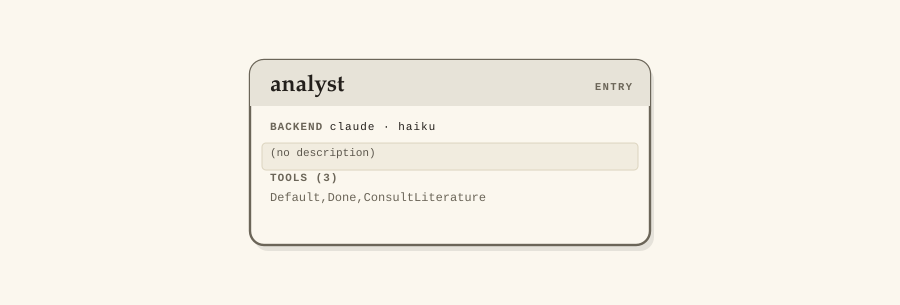

In [4]:
analyst = Agent(model="haiku", tools={"Default", "Done"})
team    = Graph(nodes={"analyst": analyst}, entry="analyst")

run = AgenticRun("car_f3dasm", graph=team, budget=900, runtime=LEAN, interactive=False, review_statement=False)
display(SVG(filename=run.render_architecture()))

**Note.** `budget=900` is the time the run may take, in seconds. `interactive=False` lets the run go on without asking us questions, and `review_statement=False` skips the review of the statement that `adda` runs before the agents start (it is only advice). `LEAN`, in the first cell, switches off what `adda` adds for long studies: a notebook `pipeline.ipynb` as deliverable with a check that it reproduces the result, hypotheses the agents must try to falsify, and the monitors of the science. Each switch is described in the [runtime reference](https://bessagroup.github.io/adda/runtime-reference/).

## Running the study

`execute()` runs the team and returns the final report of the entry node. Running an agent costs time and money, so we run it **only once**, and save the report in the study folder.

In [5]:
study = Path("car_f3dasm")
if not (study / "REPORT.md").exists():     # the agents run only if there is no report yet
    (study / "REPORT.md").write_text(str(run.execute()))
display(Markdown((study / "REPORT.md").read_text()))

Deliverables: generate_data.py samples 30 speeds in [3,82] with f3dasm sobol_sampler (seed 0), draws one reaction time z ~ N(1.5, 0.5^2) per driver (seed 0), computes y = z*x + 0.1*x^2, and stores an ExperimentData in data/ (input x; outputs z, y; 30 rows each in input.csv/output.csv/jobs.csv). predict.py fits PolynomialFeatures(degree=2)+LinearRegression on x->y and exposes predict(x). Checks: predict(10)=25.8 m vs true mean 25 m; predict(82)=806.9 m vs true mean 795 m; training R^2 about 0.994, RMSE about 18 m. Falsification: the fitted intercept (about 7.1 m) is nonzero although the true mean curve has none, and residuals grow with speed as expected from z-scatter; this was a sanity check, not a held-out test. Evaluations: 0 (no ground-truth evaluator registered; surrogate-only study). Residual uncertainty: 30 drivers is a small sample for the linear coefficient, so the fit is a noisy estimate of 1.5*x + 0.1*x^2 and is not held-out validated. Pre-existing deletions of tracked files (REPORT.md, old data files, prior run artifacts) were present before this work and were not touched; nothing was committed.

### The study folder after the run

In [6]:
# @title Code: a table of the files in a study folder (optional)
ABOUT = {"PROBLEM_STATEMENT.md": ("us", "the problem"), "REPORT.md": ("us", "the report that execute() returned"),
         "architecture.svg": ("us", "the drawing of the team, by render_architecture()"),
         "runs": ("adda", "the record of each run: transcripts, costs, status")}

def show_study(study, agent_files={}):
    """Each file and folder of a study, who wrote it, and what it is (agent_files: the files that the statement asks for)."""
    rows = ["| | written by | what |", "|---|---|---|"]
    for p in sorted(study.iterdir()):
        if p.name == "__pycache__": continue # Python's own cache
        kind = "Python code" if p.suffix == ".py" else ("a folder" if p.is_dir() else "a file")
        who, what = ABOUT.get(p.name, ("the agent", agent_files.get(p.name, kind)))
        rows.append(f"| `{p.name}{'/' if p.is_dir() else ''}` | {who} | {what} |")
    display(Markdown("\n".join(rows)))

In [7]:
show_study(study, {"data": "the experiments, an ExperimentData", "predict.py": "the model, our deliverable"})

| | written by | what |
|---|---|---|
| `PROBLEM_STATEMENT.md` | us | the problem |
| `REPORT.md` | us | the report that execute() returned |
| `architecture.svg` | us | the drawing of the team, by render_architecture() |
| `data/` | the agent | the experiments, an ExperimentData |
| `generate_data.py` | the agent | Python code |
| `predict.py` | the agent | the model, our deliverable |
| `runs/` | adda | the record of each run: transcripts, costs, status |

## The record is an `ExperimentData`

The agent stored its experiments as the statement asked. We read them back as in Lecture 18, and compare its model with the truth:

In [8]:
record = ExperimentData.from_file(study / "data")
inputs, outputs = record.to_pandas() # the inputs and the outputs, as pandas tables
x, y = inputs["x"], outputs["y"]
record

jobs     input      output          
                     x           y         z
0   finished   3.00000    5.588595  1.562865
1   finished  42.50000  241.567772  1.433948
2   finished  62.25000  500.814405  1.820211
3   finished  22.75000   87.074489  1.552450
4   finished  32.62500  146.638456  1.232165
..       ...       ...         ...       ...
25  finished  54.84375  385.627310  1.547006
26  finished  74.59375  640.583180  1.128250
27  finished  35.09375  159.624354  1.039137
28  finished  25.21875   95.655024  1.271137
29  finished  64.71875  523.055162  1.610098

[30 rows x 4 columns]

In [9]:
# @title Code: load predict(x) from a file the agents wrote (optional)
def load_predict(path):
    """The function predict(x) that the agents wrote."""
    spec = importlib.util.spec_from_file_location("predict_module", path)
    module = importlib.util.module_from_spec(spec); spec.loader.exec_module(module)
    return module.predict

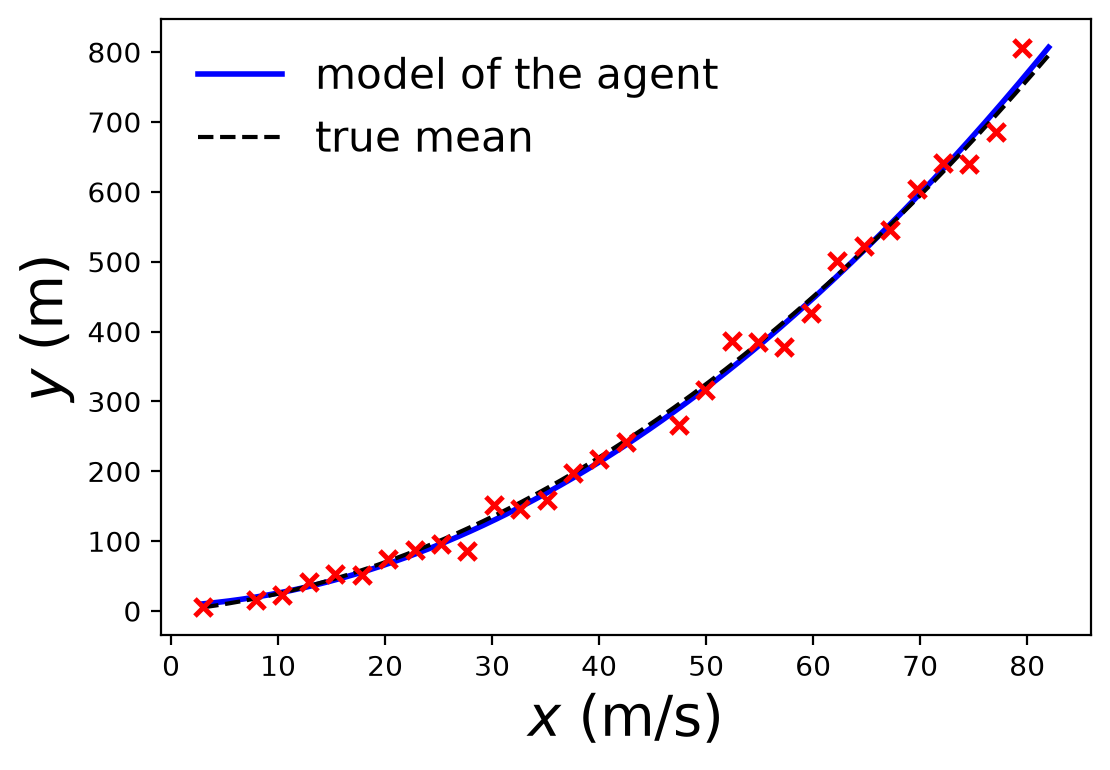

In [10]:
predict = load_predict(study / "predict.py")
xs = np.linspace(3, 82, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(xs, [float(np.squeeze(predict(v))) for v in xs], "b", lw=2, label="model of the agent")
ax.plot(xs, 1.5 * xs + 0.1 * xs**2, "k--", lw=1.5, label="true mean")
ax.scatter(x, y, s=38, color="r", marker="x", linewidths=1.8, zorder=3)
ax.set_xlabel("$x$ (m/s)", fontsize=20); ax.set_ylabel("$y$ (m)", fontsize=20)
ax.legend(loc="upper left", frameon=False, fontsize=15); plt.show()

## More flexibility: our own tool

So far the agent knew the equation. In a real study it does not, and each measurement is an experiment that we pay for.

An agent acts through its **tools**. We can give it a tool of our own, written as a **Python function**:

* the **docstring** tells the agent what the tool does
* whatever the function returns, the agent reads

The equation stays in our notebook, and the tool refuses a 31st measurement.

In [11]:
measured = {"x": [], "y": []} # our record of every measurement

def Measure(x: float) -> str:
    """Stopping distance y (m) of one new driver at speed x (m/s), x in [3, 82]. At most 30 calls."""
    if len(measured["x"]) >= 30 or not 3 <= x <= 82:
        return "ERROR: x must be in [3, 82], and at most 30 measurements."
    y = rng.normal(1.5, 0.5) * x + 0.1 * x ** 2
    measured["x"].append(x); measured["y"].append(y)
    return f"y = {y:.3f} m"

### An agent with our tool

We list our function among the tools of the agent. The agent sees it by its name, `Measure`.

In [12]:
analyst = Agent(model="haiku", tools={"Default", "Done", Measure})
team    = Graph(nodes={"analyst": analyst}, entry="analyst")

### The study, with the tool

A new statement, without the equation. The goal is now a model of the mean **and** of the standard deviation.

In [13]:
Path("car_tool").mkdir(exist_ok=True)

In [14]:
%%writefile car_tool/PROBLEM_STATEMENT.md
A car at speed x (m/s) stops after y metres; y differs per driver, and its equation is unknown. Measure(x) returns y
for one new driver, at most 30 times. Build a model of the mean mu(x) and the standard deviation sd(x) of y, such that
mu +- 1.96 sd contains 95% of the drivers at any x in [3, 82], and write predict.py with predict(x) -> (mu, sd).

Overwriting car_tool/PROBLEM_STATEMENT.md


In [15]:
study = Path("car_tool")
if not (study / "REPORT.md").exists():
    run = AgenticRun(study, graph=team, budget=900, runtime=LEAN, interactive=False, review_statement=False)
    (study / "REPORT.md").write_text(str(run.execute()))
    # our record of the measurements, as an ExperimentData (Lecture 18)
    ExperimentData(input_data=pd.DataFrame(measured)[["x"]], output_data=pd.DataFrame(measured)[["y"]],
                   project_dir=study).store()
display(Markdown((study / "REPORT.md").read_text()))

Model: mu(x) = 1.7323·x + 0.09520·x² (m); sd(x) = 3.991 + 0.3036·x (m), floored at 0.5. Written to predict.py as predict(x) -> (mu, sd). Data: all 30 Measure() calls used (21 grid points over [3,82] plus 9 replicates: 4 at x=14, 3 at x=50, 3 at x=82). Checks: quadratic mean RMS residual 18.0 m vs cubic 17.2 m (quadratic kept for physical form, y(0)=0). Replicate sds: 11.0 (x=14), 22.7 (x=50), 19.8 (x=82); the linear sd fit gives 8.2, 19.2, 28.9. In-sample 1.96·sd coverage 29/30. Falsification: the replicate sds were used as a check on the sd model; it agrees at x=14 and x=50 but not at x=82 (observed 19.8 vs predicted 28.9). Remaining uncertainty: sd is estimated from 30 points, so the band could be off by tens of percent at specific x; coverage at x=82 may be conservative. No evaluations remain, so the budget cannot settle this further.

## Our record is an `ExperimentData`

Every measurement went through our tool, so our record is complete, and the agent cannot edit it:

In [16]:
record = ExperimentData.from_file(study)
x, y = record.to_numpy()
print("measurements:", len(record))

measurements: 30


In [17]:
# @title Code: the 95% band of a model and the true band (optional)
def plot_band(predict, x_measured, y_measured):
    """The 95% band of a model, the true 95% band, and the measurements."""
    xs = np.linspace(3, 82, 200)
    mu, sd = np.array([predict(float(v)) for v in xs]).T
    true_mu, true_sd = 1.5 * xs + 0.1 * xs**2, 0.5 * xs
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.fill_between(xs, mu - 1.96 * sd, mu + 1.96 * sd, color="b", alpha=0.25, lw=0, label="model of the agent")
    ax.plot(xs, true_mu - 1.96 * true_sd, "k--", lw=1.5, label="truth")
    ax.plot(xs, true_mu + 1.96 * true_sd, "k--", lw=1.5)
    ax.scatter(x_measured, y_measured, s=38, color="r", marker="x", linewidths=1.8, zorder=3)
    ax.set_xlabel("$x$ (m/s)", fontsize=20); ax.set_ylabel("$y$ (m)", fontsize=20)
    ax.legend(loc="upper left", frameon=False, fontsize=15)
    plt.show()

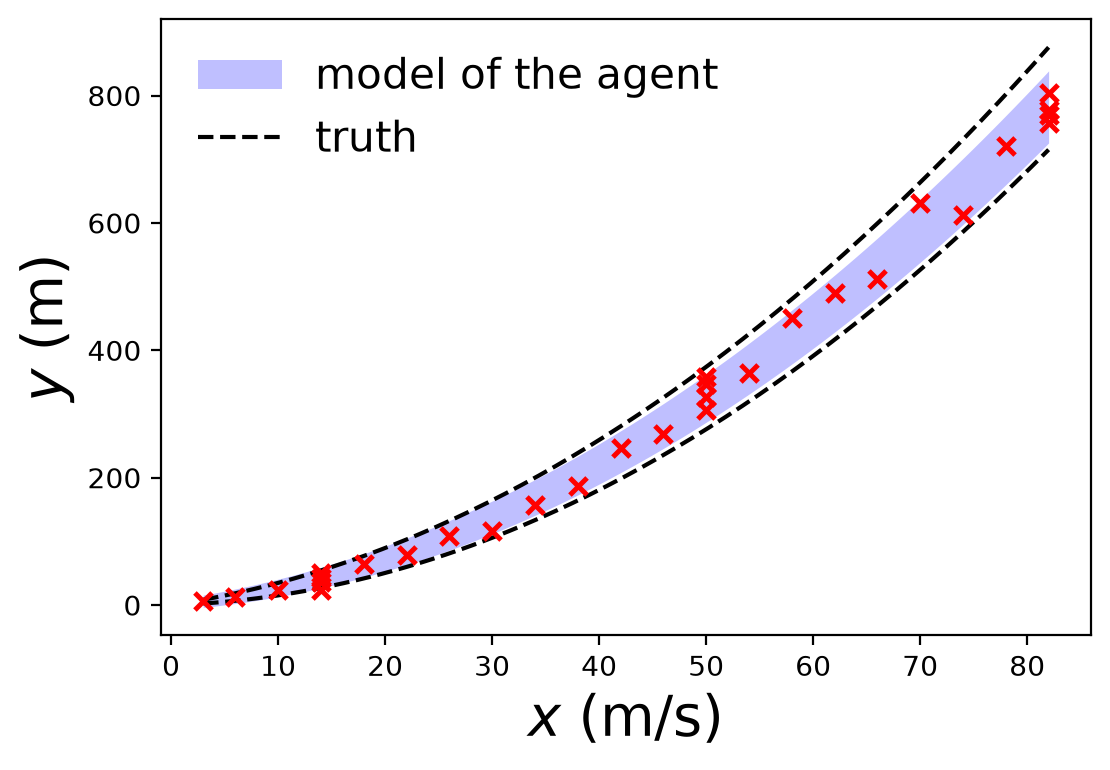

In [18]:
plot_band(load_predict(study / "predict.py"), x, y)

**Note.** When the experiment is an evaluator declared to `adda` (see the [study guide](https://bessagroup.github.io/adda/author-a-study/)), `adda` keeps a record of the same kind, in `runs/<timestamp>/experiment_data/`, with the agent that made each measurement. It loads with `ExperimentData.from_file` as well.

## More flexibility: a model for each agent

Each node has its own model, `Agent(model=...)`. In this course, and in the Final Project, every agent uses Haiku. The same syntax gives another model to another node, for example a larger one to the node that plans:

```python
Graph(nodes={"planner": Agent(model="sonnet", tools={"Read"}),
             "builder": Agent(model="haiku",  tools={"Default"})}, ...)
```

### In-class Exercise 1

Change `Measure` so that it allows only **15** measurements, and run the study again in a new folder `car_tool_15`.

1. How does the band of the model change?
2. What does the agent write about its choice of speeds?

## Summary of today

| | syntax |
|---|---|
| a study | a folder with `PROBLEM_STATEMENT.md` |
| an agent | `Agent(model="haiku", tools={"Default", "Done"})` |
| our own tool | a Python function with a docstring, listed in `tools` |
| a team | `Graph(nodes={...}, entry=...)` |
| draw it, run it | `run = AgenticRun(study, graph=team)`, then `run.render_architecture()`, `run.execute()` |
| its record | `ExperimentData.from_file(...)` |

The agents do the work. The problem, the tools and the checks are ours.

## Field guide: what this lecture adds

### Good practices

**7. Work with an AI coding agent**
- **Check against something you know**, not against "the code runs": e.g. the normal equations, or "the training error cannot increase with the degree".
- **A team of agents is a graph**: each node is an agent with its own prompt, tools and model, and each edge says who may hand work to whom. Start with one node.
- **The statement is the specification**: state the objective, the inputs with bounds and units, the budget, and the deliverables.
- **Keep the truth in your own code**: an agent can read every file it reaches, so what it must not read or edit (the equation, your record of the experiments) goes in a tool.
- **A limit in a tool is a limit**: a tool can refuse a call, while a limit written in the statement is only a request.

The whole [field guide](https://github.com/bessagroup/3dasm_course/blob/main/FIELD_GUIDE.md) collects the key concepts and good practices of every lecture.

### See you next class

Next lecture: a team with more than one agent, and how to make its results checkable.

Have fun!